<a href="https://colab.research.google.com/github/San-Maansson/Machine_Learning/blob/main/Pytorch_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import matplotlib.pyplot as plt
import torch
import pandas as pd
import numpy as np
import seaborn as sns
from torch import nn
from time import time
from tqdm import tqdm
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_curve, auc, precision_recall_curve, confusion_matrix
)

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Set visual style
sns.set(style='whitegrid', palette='muted')

Text(0, 0.5, 'Price ($10,000s)')

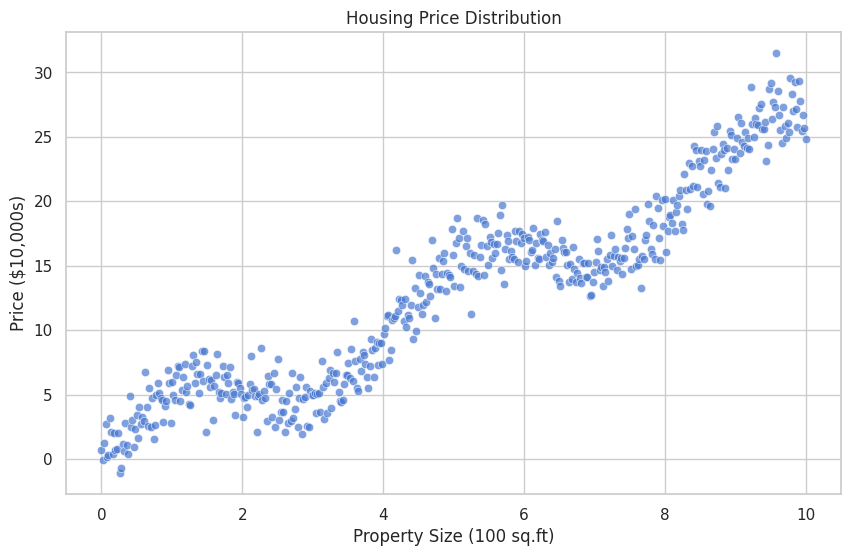

In [6]:
# Generate synthetic dataset with curvature
np.random.seed(42)
X = np.linspace(0, 10, 500) #use np.linspace to create evenly spaced feature values.
y = 2.5 * X + 3 * np.sin(X*1.5) + np.random.normal(0, 1.5, X.shape)
#Add sinusoidal curvature (sin(1.5 * X)) and Gaussian noise via np.random.normal to mimic real-world irregularities
plt.figure(figsize=(10,6))
sns.scatterplot(x=X, y=y, alpha=0.7)
plt.title("Housing Price Distribution")
plt.xlabel("Property Size (100 sq.ft)")
plt.ylabel("Price ($10,000s)")

In [8]:
# Reproducibility & Seeding

def set_seed(seed: int):
    import random
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

In [10]:
# Core Training Loop

def run_epoch(model, optimizer, loader, loss_fn, device, results,
              score_funcs={}, prefix="", desc=None):
    model.train() if model.training else model.eval()
    running_loss, y_true, y_pred = [], [], []
    start = time()
    for X_batch, y_batch in tqdm(loader, desc=desc, leave=False):
        # Move data
        Xb, yb = moveTo(X_batch, device), moveTo(y_batch, device)

        # Forward
        preds = model(Xb)
        loss = loss_fn(preds, yb)
        if model.training:
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()

        running_loss.append(loss.item())

        # Collect for metrics
        y_true.extend(yb.detach().cpu().numpy().tolist())
        y_pred.extend(preds.detach().cpu().numpy().tolist())

    # Convert and compute metrics
    if np.ndim(y_pred[0]) > 1:
        # classification → argmax
        y_pred = np.argmax(y_pred, axis=1)
    results[prefix + " loss"].append(np.mean(running_loss))
    for name, fn in score_funcs.items():
        try:
            results[prefix + " " + name].append(fn(y_true, y_pred))
        except:
            results[prefix + " " + name].append(float("nan"))
    return time() - start

    # TQDM for live progress bars and ETA
    #Zero gradients before backprop to prevent accumulation from prior batches

In [11]:
def train_simple_network(model, loss_func, train_loader, test_loader=None, score_funcs=None,
                         epochs=50, device="cpu", checkpoint_file=None, lr=0.001):

    to_track = ["epoch", "total time", "train loss"]
    if test_loader is not None:
        to_track.append("test loss")
    for eval_score in score_funcs:
        to_track.append("train " + eval_score )
        if test_loader is not None:
            to_track.append("test " + eval_score )

    total_train_time = 0 #How long have we spent in the training loop?
    results = {}
    #Initialize every item with an empty list
    for item in to_track:
        results[item] = []

    #SGD is Stochastic Gradient Decent.
    optimizer = torch.optim.SGD(model.parameters(), lr=0.001)
    #Place the model on the correct compute resource (CPU or GPU)
    model.to(device)
    for epoch in tqdm(range(epochs), desc="Epoch"):
        model = model.train()#Put our model in training mode

        total_train_time += run_epoch(model, optimizer, train_loader, loss_func, device, results, score_funcs, prefix="train", desc="Training")

        results["total time"].append( total_train_time )
        results["epoch"].append( epoch )

        if test_loader is not None:
            model = model.eval()
            with torch.no_grad():
                run_epoch(model, optimizer, test_loader, loss_func, device, results, score_funcs, prefix="test", desc="Testing")

    if checkpoint_file is not None:
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'results' : results
            }, checkpoint_file)

    return pd.DataFrame.from_dict(results)

    #A wrapper train_simple_network repeatedly calls run_epoch, tracks total time, and saves optional checkpoints.

In [13]:
# 5 Debugging Shapes & Device Placement

# 5.1 DebugShape Module
class DebugShape(nn.Module):
    def forward(self, x):
        print(f"[DebugShape] {tuple(x.shape)}")
        return x

    # Scenario: Your model raises a dimension mismatch; DebugShape pinpoints exactly which layer's output shape is unexpected.

In [14]:
# 5.2 moveTo Utility
# Recursively move tensors, lists, tuples, dicts to CPU/GPU:

def moveTo(obj, device):
    if hasattr(obj, 'to'):
        return obj.to(device)
    if isinstance(obj, (list, tuple, set)):
        return type(obj)(moveTo(x, device) for x in obj)
    if isinstance(obj, dict):
        return {moveTo(k, device): moveTo(v, device) for k, v in obj.items()}
    return obj

In [18]:
# 6 Dataset & DataLoader

class Simple1DRegressionDataset(Dataset):
    def __init__(self, X, y):
        super().__init__()
        self.X = X.reshape(-1, 1)
        self.y = y.reshape(-1, 1)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return (torch.tensor(self.X[idx], dtype=torch.float32),
                torch.tensor(self.y[idx], dtype=torch.float32))

In [19]:
# Instantiate loaders with batching and shuffling:

train_ds = Simple1DRegressionDataset(X, y)
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=2, pin_memory=True)

# Dataset/DataLoader primitives decouple data handling from modeling.
# Usepin_memory=True and multiple workers to optimize GPU data throughput on Kaggle notebooks

Training:   0%|          | 0/16 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)

Training:   0%|          | 0/16 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)

Training:   0%|          | 0/16 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)

Training:   0%|          | 0/16 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no

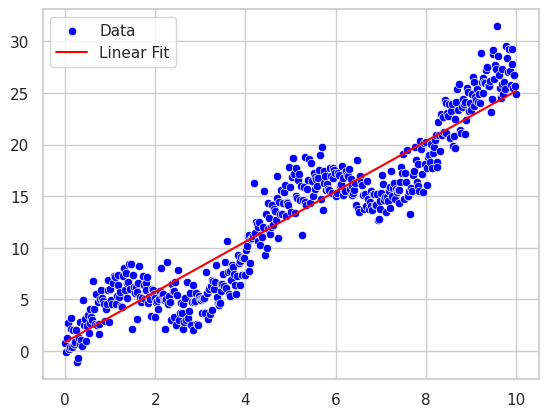

In [17]:
# 7 Model Definition & Visualization

# 7.1 Linear Model Baseline

model = nn.Linear(1, 1).to(device)
loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

# Train
linear_results = train_simple_network(model, loss_fn, train_loader, score_funcs={'Acc':accuracy_score,'F1': f1_score}, device=device)

# Visualize fit
with torch.no_grad():
    Y_pred = model(torch.tensor(X.reshape(-1,1), dtype=torch.float32, device=device)).cpu().numpy()
sns.scatterplot(x=X, y=y, color='blue', label='Data')
sns.lineplot(x=X, y=Y_pred.ravel(), color='red', label='Linear Fit')
plt.show()

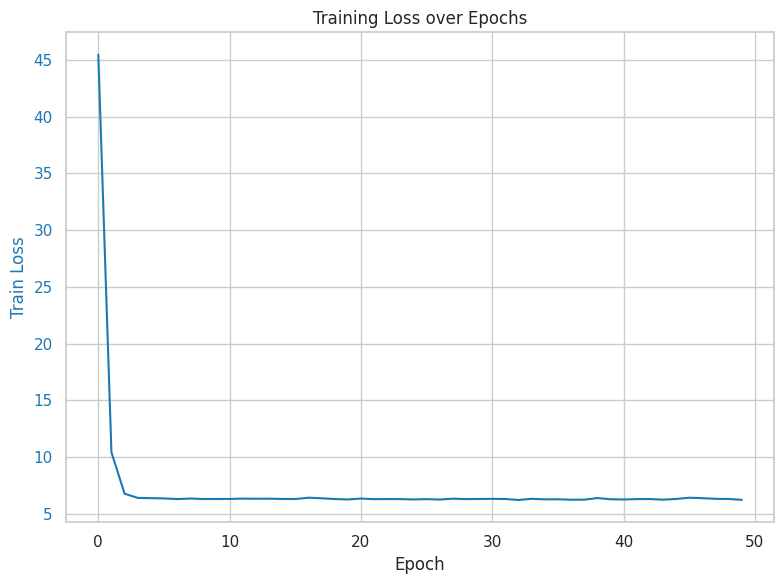

In [20]:
# Training Loss over Epochs

# Create a plot
fig, ax1 = plt.subplots(figsize=(8, 6))

# Plot 'train loss' against 'epoch'
color = 'tab:blue'
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Train Loss', color=color)
ax1.plot(linear_results['epoch'], linear_results['train loss'], color=color, label='Train Loss')
ax1.tick_params(axis='y', labelcolor=color)

# Title and layout
plt.title('Training Loss over Epochs')
fig.tight_layout()
plt.show()

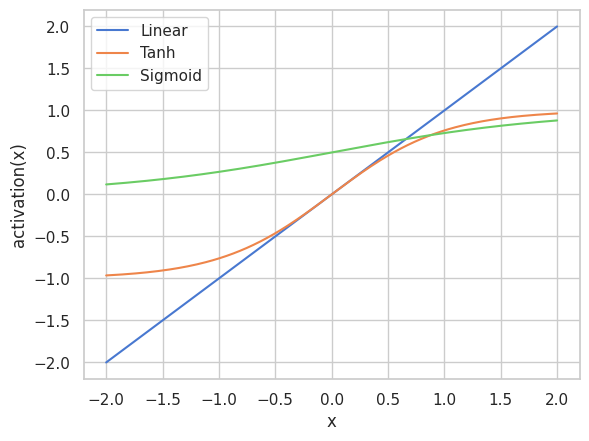

In [21]:
#8 Activation Function Visualization
# Plot common activations to build intuition:

inp = np.linspace(-2, 2, 200)
tanh = np.tanh(inp)
sigmoid = np.exp(inp) / (np.exp(inp) + 1)

sns.lineplot(x=inp, y=inp, label='Linear')
sns.lineplot(x=inp, y=tanh, label='Tanh')
sns.lineplot(x=inp, y=sigmoid, label='Sigmoid')
plt.xlabel('x'); plt.ylabel('activation(x)')
plt.show()

Training:   0%|          | 0/16 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)

Training:   0%|          | 0/16 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)

Training:   0%|          | 0/16 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)

Training:   0%|          | 0/16 [00:00<?, ?it/s]/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no

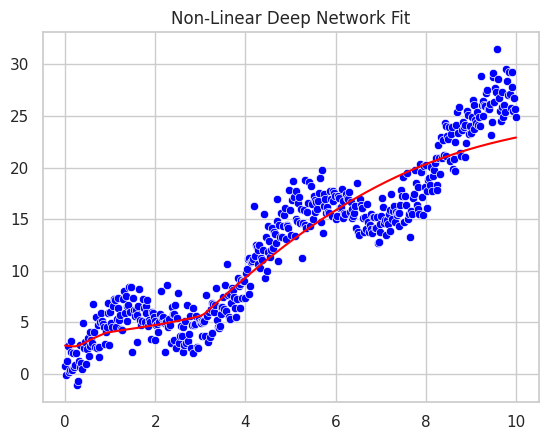

In [22]:
# Introducing Non-Linearity & Layer Depth

model = nn.Sequential(
    nn.Linear(1, 64), nn.ReLU(),
    nn.Linear(64, 32), nn.Tanh(),
    nn.Linear(32, 1)
).to(device)

non_linear_results = train_simple_network(model, loss_fn, train_loader, score_funcs={'Acc':accuracy_score,'F1': f1_score}, device=device)

# Plot predictions
with torch.no_grad():
    Y_pred = model(torch.tensor(X.reshape(-1,1), dtype=torch.float32, device=device)).cpu().numpy()
sns.scatterplot(x=X, y=y, color='blue')
sns.lineplot(x=X, y=Y_pred.ravel(), color='red')
plt.title("Non-Linear Deep Network Fit")
plt.show()

# Stacking layers + activations lets the model capture complex curves.
# Monitor for overfitting by comparing training and validation losses in your results DataFrame.

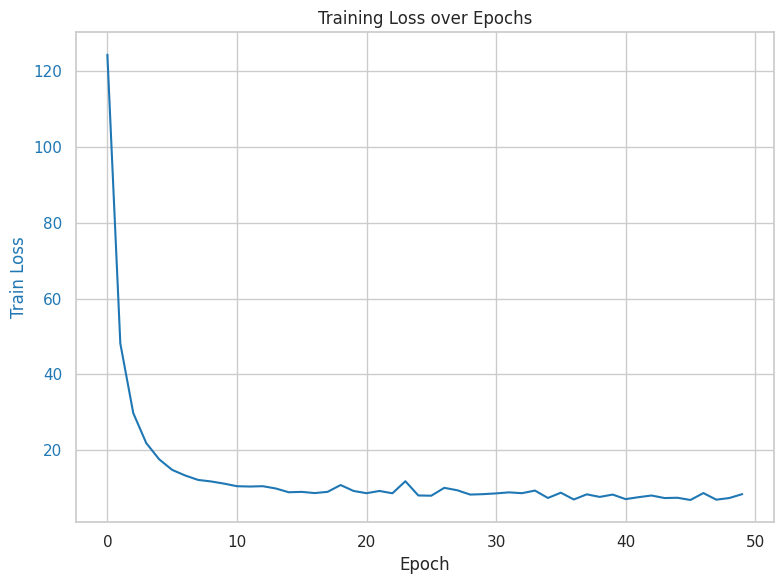

In [23]:
import matplotlib.pyplot as plt

# Create a plot
fig, ax1 = plt.subplots(figsize=(8, 6))

# Plot 'train loss' against 'epoch'
color = 'tab:blue'
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Train Loss', color=color)
ax1.plot(non_linear_results['epoch'], non_linear_results['train loss'], color=color, label='Train Loss')
ax1.tick_params(axis='y', labelcolor=color)

# Title and layout
plt.title('Training Loss over Epochs')
fig.tight_layout()
plt.show()